# Example of the aitlas toolbox in the context of object detection 

This notebook shows a sample implementation of object detection using the aitlas toolbox. The DLR-MVDA dataset contains cars annotated with oriented bounding boxes. For ease of use, this notebook translates them into axis-aligned bounding boxes.

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import DLRMVDADAtaset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

In [ ]:
dataset_config = {
    "data_dir": "./data/dlr_mvda/Train",
    "annotation_dir": "./data/dlr_mvda/Train",
}
dataset = DLRMVDADAtaset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 563


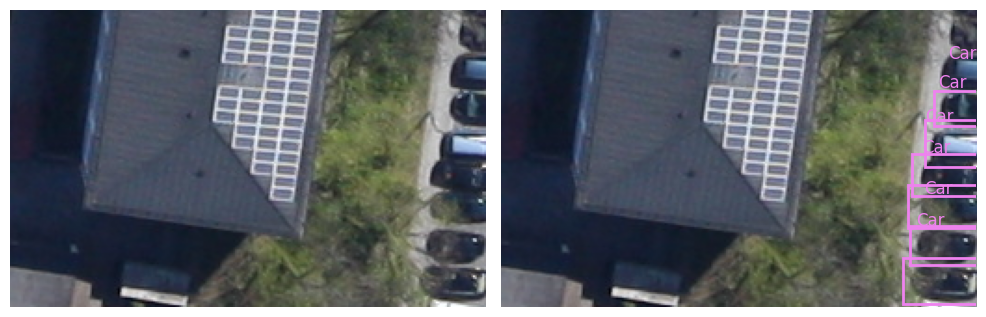

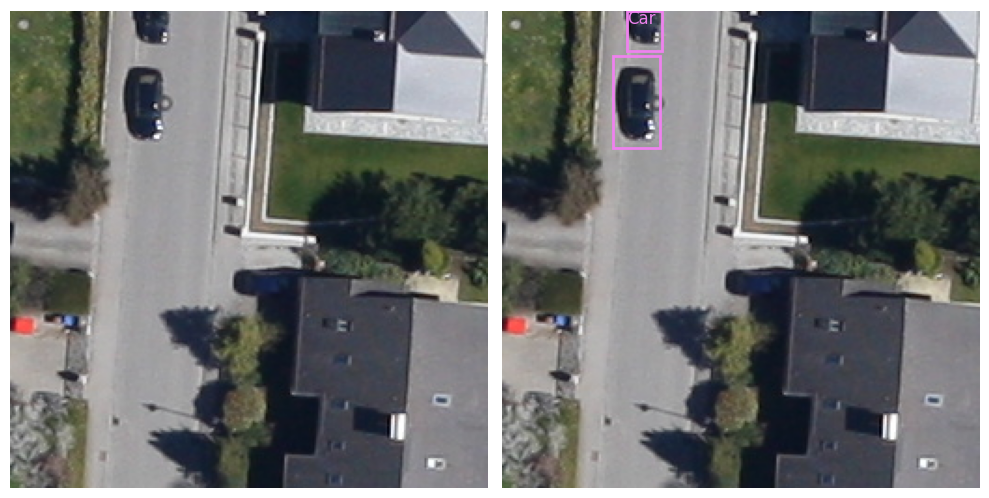

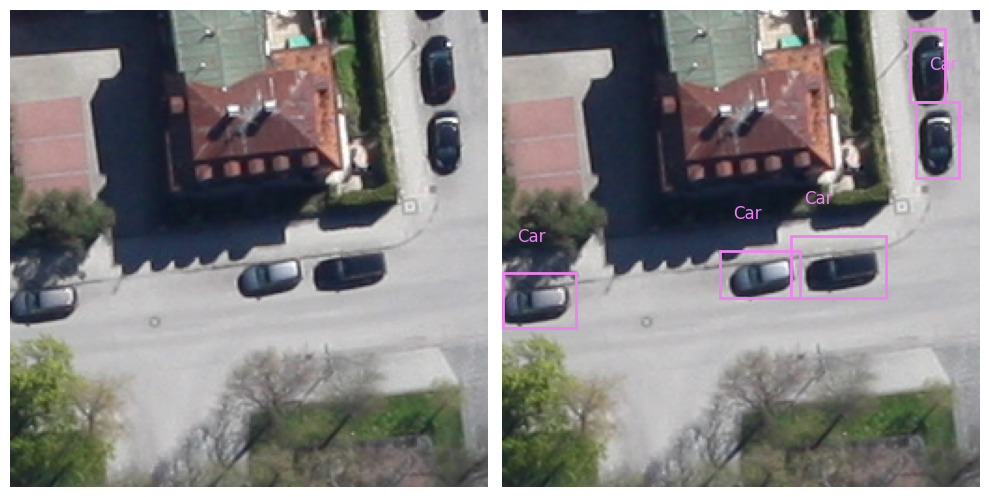

In [22]:
dataset.show_image(300);
dataset.show_image(10);
dataset.show_image(200);

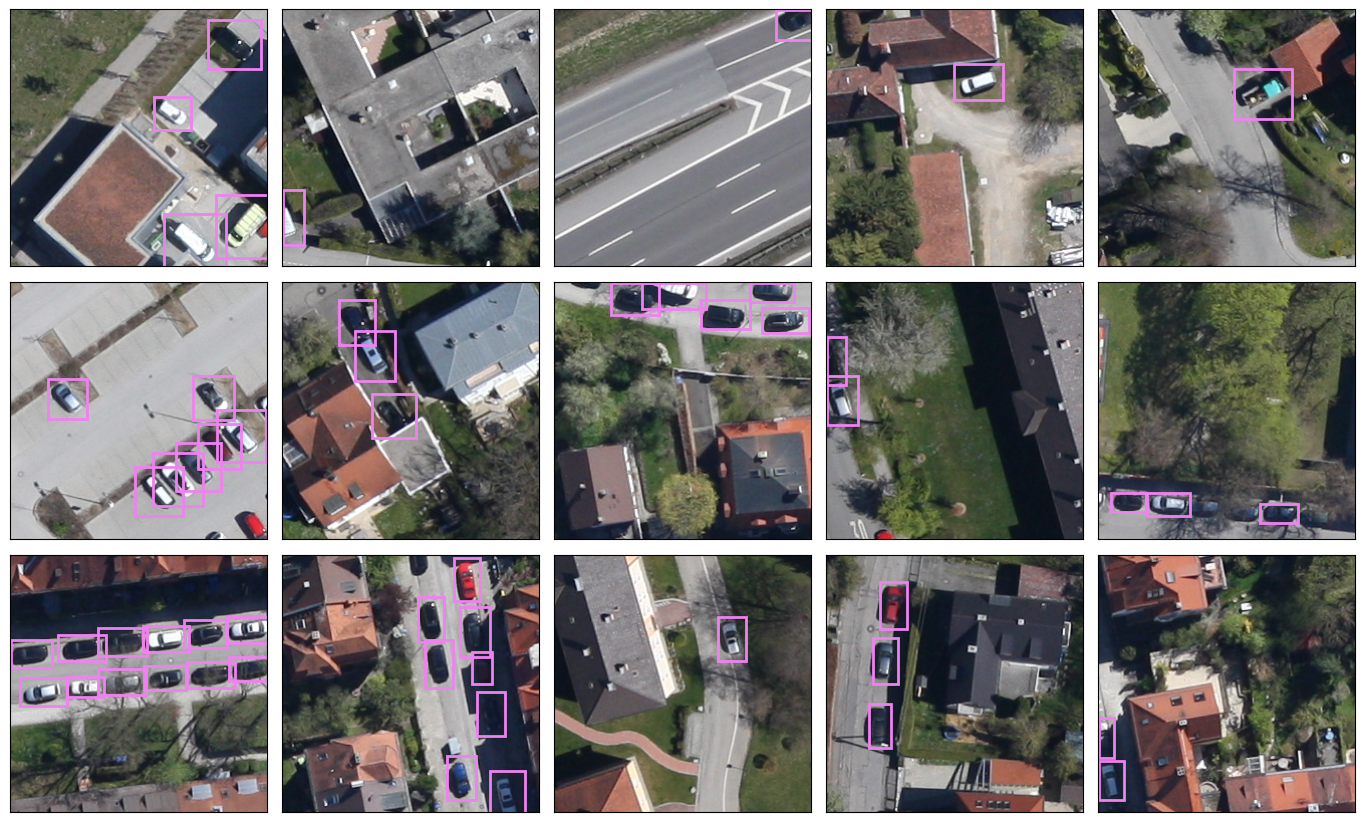

In [46]:
dataset.show_batch(15);

In [68]:
dataset.data_distribution_table()

,Label,Count
0,Car,3192
1,Car with a Trailer,2
2,Truck,54
3,Truck with a Trailer,7
4,Van,227
5,Van with a Trailer,3
6,Long truck,8
7,Bus,12


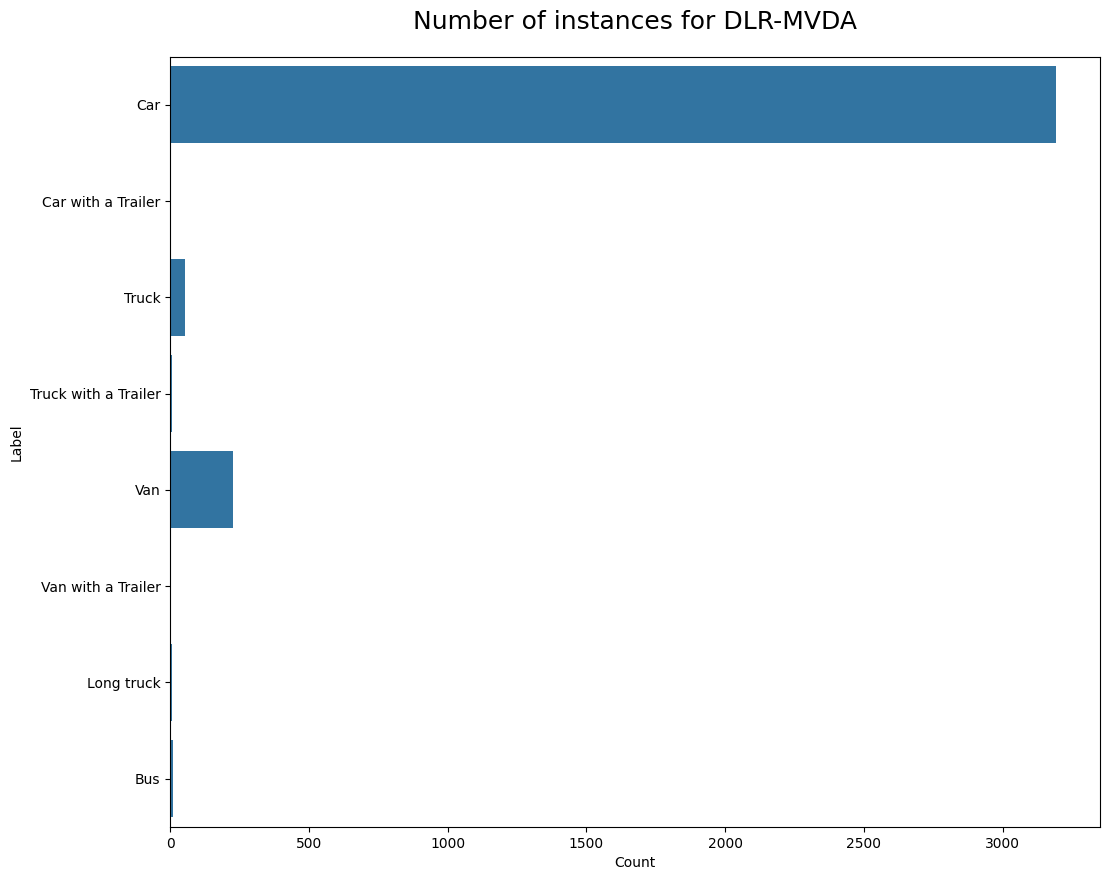

In [69]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/dlr_mvda/Train",
    "annotation_dir": "./data/dlr_mvda/Train",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = DLRMVDADAtaset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 805


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiments/DLR_MVDA/"
model_config = {
    "num_classes": 9,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [55]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-18 13:52:49,472 INFO Starting training.
training: 100%|██████████| 101/101 [00:47<00:00,  2.13it/s]
2025-09-18 13:53:36,893 INFO epoch: 1, time: 47, loss:  0.42590
testing on train set: 100%|██████████| 101/101 [00:46<00:00,  2.18it/s]
2025-09-18 13:54:26,070 INFO map:0.08413680642843246, map_50:0.119939886033535, map_75:0.10492453724145889, map_small:0.031715527176856995, map_medium:0.16921871900558472, map_large:0.07067825645208359, mar_1:0.024827219545841217, mar_10:0.08709652721881866, mar_100:0.09454697370529175, mar_small:0.16249999403953552, mar_medium:0.1901249885559082, mar_large:0.0833333358168602, map_per_class:tensor(0.6722), tensor(0.), tensor(0.), tensor(0.), tensor(0.0009), tensor(0.), tensor(0.), tensor(0.), mar_100_per_class:tensor(0.7508), tensor(0.), tensor(0.), tensor(0.), tensor(0.0056), tensor(0.), tensor(0.), tensor(0.), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32), tensor(4, dtype=torch.int32), tensor(5

0.07555956029049728

## Predictions

2025-09-18 14:11:21,002 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/DLR_MVDA/checkpoint.pth.tar
2025-09-18 14:11:21,283 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/DLR_MVDA/checkpoint.pth.tar at epoch 11


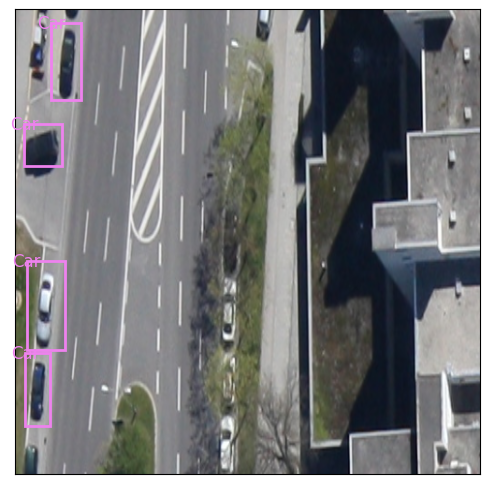

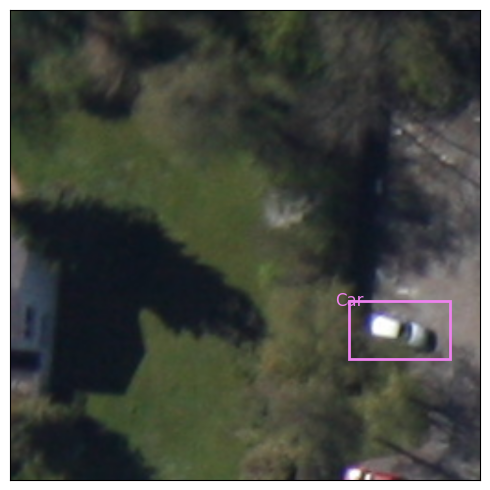

In [ ]:
model_config = {
    "num_classes": 9,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/DLR_MVDA/checkpoint.pth.tar"
labels = ["no-data","Car","Car with a Trailer","Truck","Truck with a Trailer","Van","Van with a Trailer","Long truck","Bus"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/dlr_mvda/Test/2012-04-26-Muenchen-Tunnel_4K0G0110.JPG')[256:512,512:1024,:] # 256x256 patch
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/dlr_mvda/Test/2012-04-26-Muenchen-Tunnel_4K0G0250.JPG')[:256,:256,:]
fig = model.detect_objects(image, labels, transform)